# Tarea de la semana: Análisis de series temporales (Ventas)



## 1. Datos, resample y media móvil
Las ventas diarias (sintéticas, semilla 42) se agregan a totales mensuales con `resample('MS')` y luego se suavizan con medias móviles de 3 y 12 meses.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)
days = pd.date_range("2022-01-01", "2024-12-31", freq="D")
t = np.arange(len(days))
season = 1 + 0.30 * np.sin(2 * np.pi * (days.dayofyear - 300) / 365.25)
sales = np.asarray((1000 + 0.35 * t) * season) + rng.normal(0, 60, len(days))
region = rng.choice(["Norte", "Sur"], len(days), p=[0.6, 0.4])
df = pd.DataFrame({"fecha": days, "ventas": np.clip(sales, 0, None), "region": region})
df.to_csv("ventas.csv", index=False)
# Para usar datos reales: df = pd.read_csv("ventas.csv", parse_dates=["fecha"])

monthly = df.set_index("fecha")["ventas"].resample("MS").sum().to_frame("ventas")
monthly["ma3"] = monthly["ventas"].rolling(3).mean()
monthly["ma12"] = monthly["ventas"].rolling(12).mean()
print(monthly.round(0).tail(6))


             ventas      ma3     ma12
fecha                                
2024-07-01  29691.0  31876.0  38465.0
2024-08-01  29613.0  29753.0  38703.0
2024-09-01  32917.0  30740.0  39026.0
2024-10-01  39733.0  34087.0  39352.0
2024-11-01  45482.0  39377.0  39760.0
2024-12-01  52492.0  45902.0  40218.0


### Cifras de tendencia y estacionalidad

In [2]:
yearly = monthly["ventas"].resample("YS").sum()
print("Yearly totals:\n", yearly.round(0))
print("\nYoY growth %:\n", (yearly.pct_change().dropna() * 100).round(1))

monthly["year"] = monthly.index.year
monthly["month"] = monthly.index.month
monthly["share"] = monthly["ventas"] / monthly.groupby("year")["ventas"].transform("sum") * 100
season_profile = monthly.groupby("month")["share"].mean()
print("\nSeasonal profile (% of year):\n", season_profile.round(1))
print("Peak month:", season_profile.idxmax(), "| Low month:", season_profile.idxmin())
print("Peak/low ratio:", round(season_profile.max() / season_profile.min(), 2))


Yearly totals:
 fecha
2022-01-01    387028.0
2023-01-01    431978.0
2024-01-01    482615.0
Freq: YS-JAN, Name: ventas, dtype: float64

YoY growth %:
 fecha
2023-01-01    11.6
2024-01-01    11.7
Freq: YS-JAN, Name: ventas, dtype: float64

Seasonal profile (% of year):
 month
1     10.5
2      9.6
3      9.8
4      8.5
5      7.5
6      6.3
7      6.1
8      6.2
9      6.8
10     8.3
11     9.5
12    10.9
Name: share, dtype: float64
Peak month: 12 | Low month: 7
Peak/low ratio: 1.79


## 2. Visualizaciones
### Gráfica 1 – Evolución

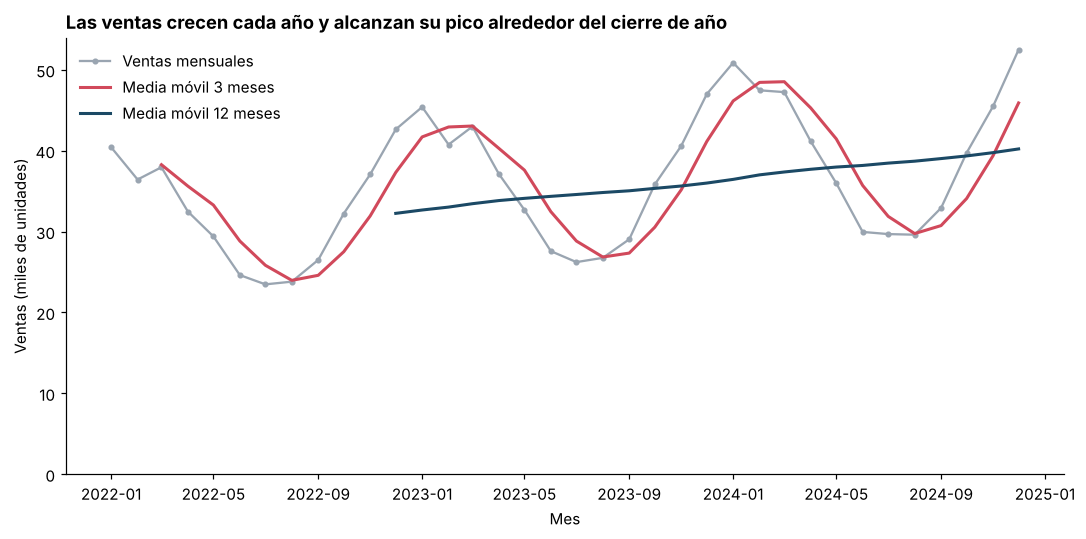

In [3]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(monthly.index, monthly["ventas"] / 1000, color="#9aa5b1", marker="o", ms=3, label="Ventas mensuales")
ax.plot(monthly.index, monthly["ma3"] / 1000, color="#d1495b", lw=2, label="Media móvil 3 meses")
ax.plot(monthly.index, monthly["ma12"] / 1000, color="#1b4965", lw=2, label="Media móvil 12 meses")
ax.set_ylim(0, None)
ax.set_title("Las ventas crecen cada año y alcanzan su pico alrededor del cierre de año", loc="left", fontweight="bold")
ax.set_xlabel("Mes"); ax.set_ylabel("Ventas (miles de unidades)")
ax.legend(frameon=False); ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout(); fig.savefig("evolution.png", dpi=150)


### Gráfica 2 – Comparación (participación en las ventas anuales por mes del calendario)

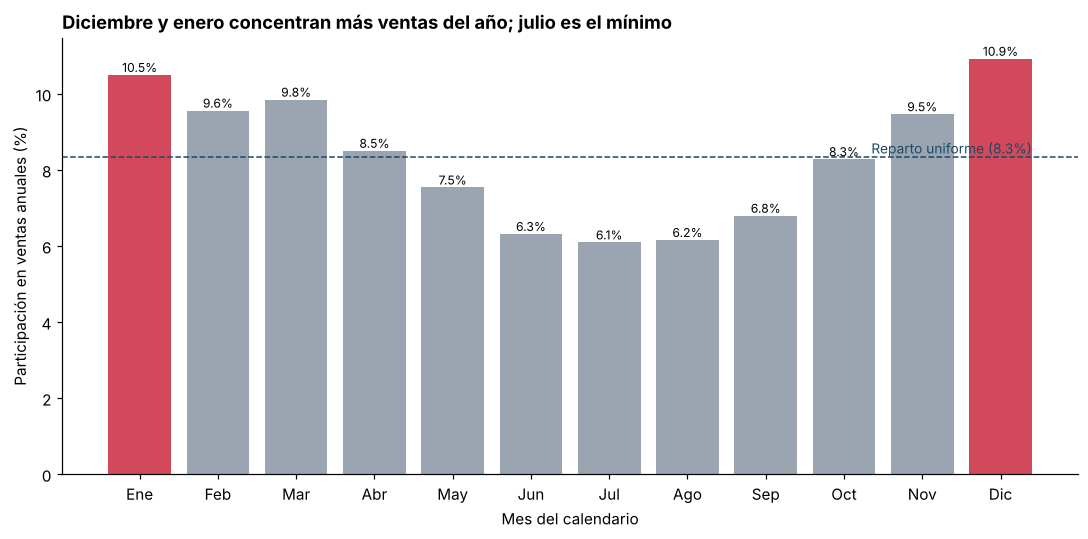

In [4]:
fig, ax = plt.subplots(figsize=(10, 5))
names = ["Ene","Feb","Mar","Abr","May","Jun","Jul","Ago","Sep","Oct","Nov","Dic"]
colors = ["#d1495b" if m in (12, 1) else "#9aa5b1" for m in season_profile.index]
bars = ax.bar(names, season_profile.values, color=colors)
ax.bar_label(bars, fmt="%.1f%%", fontsize=8)
ax.axhline(100 / 12, color="#1b4965", ls="--", lw=1)
ax.text(11.4, 100 / 12 + 0.1, "Reparto uniforme (8.3%)", ha="right", color="#1b4965", fontsize=9)
ax.set_ylim(0, None)
ax.set_title("Diciembre y enero concentran más ventas del año; julio es el mínimo", loc="left", fontweight="bold")
ax.set_xlabel("Mes del calendario"); ax.set_ylabel("Participación en ventas anuales (%)")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout(); fig.savefig("seasonality_comparison.png", dpi=150)


## 3. Medidas DAX
```dax
-- Supone la tabla de hechos Ventas[fecha], Ventas[ventas] y una tabla de fechas marcada Calendario[Fecha]

Total Sales = SUM ( Ventas[ventas] )

Sales 3M Moving Avg =
VAR Last3M =
    DATESINPERIOD ( Calendario[Fecha], MAX ( Calendario[Fecha] ), -3, MONTH )
RETURN
    DIVIDE ( CALCULATE ( [Total Sales], Last3M ), 3 )

Sales YoY % =
VAR Prev = CALCULATE ( [Total Sales], SAMEPERIODLASTYEAR ( Calendario[Fecha] ) )
RETURN DIVIDE ( [Total Sales] - Prev, Prev )
```
`Total Sales` es el indicador base. `Sales 3M Moving Avg` suaviza el ruido mensual: suma los últimos 3 meses con `DATESINPERIOD` y los divide entre 3 (se usa en una visual con granularidad mensual; en los primeros 2 meses de datos el valor es parcial). `Sales YoY %` compara cada periodo con el mismo periodo del año anterior, lo que elimina la estacionalidad de la comparación; `DIVIDE` evita errores de división entre cero.


## 4. Findings
_(Esta sección va en inglés porque así lo pide la tarea.)_

Daily sales were resampled to monthly totals (`resample("MS")`) and smoothed with 3-month and 12-month moving averages. The trend is clearly upward: yearly totals rose from about 387k units in 2022 to 432k in 2023 and 483k in 2024, which is roughly 11.6% and 11.7% year-over-year growth. The 12-month moving average climbs smoothly over the whole period, confirming that the growth is steady and not driven by one-off spikes. There is also a strong yearly seasonality: December (10.9% of annual sales) and January (10.5%) are the peak months, while July is the lowest (6.1%), a peak-to-low ratio of about 1.8. The first chart (evolution) shows monthly sales as grey points, the 3-month average in red, which follows the seasonal waves, and the 12-month average in dark blue, which isolates the underlying growth. The second chart (comparison) shows the average share of annual sales for each calendar month, with the dashed line marking an even split of 8.3%, so it is easy to see which months are above or below normal. Both charts start their y-axis at zero so the size of the seasonal swings and the growth is not exaggerated. The practical takeaway is that comparing a winter month to a summer month is misleading, and year-over-year growth (as in the `Sales YoY %` measure) is the fairer way to judge performance.
